In [65]:
import torch
import numpy as np
import cv2

import torchvision.transforms as T
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from sklearn.model_selection import StratifiedKFold
from torch import Tensor
from torch.nn import Sequential, Linear, ReLU, CrossEntropyLoss, Module, Dropout, Flatten, Conv2d, MaxPool2d, AdaptiveAvgPool2d, BatchNorm2d
from torch.utils.data import DataLoader, Dataset
from torch.optim import Adam
from pathlib import Path
import matplotlib.pyplot as plt

In [66]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

### Transformação com Augmentation ( SÓ Treino )

In [67]:
# Transformação com Augmentation ( SÓ Treino )
train_transform = T.Compose([
    T.ToPILImage(),
    T.RandomHorizontalFlip(p = 0.5),
    T.RandomVerticalFlip(p = 0.5),
    T.RandomRotation(degrees = 90),
    T.ToTensor(),
])

# Transformação sem Augmentation ( SÓ Teste/Validação )
val_transform = T.Compose([
    T.ToPILImage(),
    T.ToTensor(), # Converte para Tensor e já divide por 255
])

In [68]:
class MyDataset(Dataset):
    def __init__(self, datas: np.ndarray, labels: np.ndarray, transform=None) -> None:
        self.datas = datas
        self.labels = torch.from_numpy(labels).long()
        self.transform = transform

    def __len__(self) -> int:
        return len(self.datas)

    def __getitem__(self, idx: int) -> tuple[Tensor, Tensor]:
        image = self.datas[idx].astype(np.uint8)
        label = self.labels[idx]

        if self.transform:
            image = self.transform(image)
        else:
            # Casa não tenha transform, converte para tensor e normaliza
            image = torch.from_numpy(image).float().unsqueeze(0) / 255.0
        
        return image.to(device), label.to(device)



    

In [69]:
class CustomModel(Module):
    def __init__(self, output_size: int) -> None:
        super().__init__()

        self.net = Sequential(
            Conv2d(1, 16, kernel_size=3, padding=1),
            BatchNorm2d(16),
            ReLU(),
            MaxPool2d(kernel_size=2),
            Conv2d(16, 32, kernel_size=3, padding=1),
            BatchNorm2d(32),
            ReLU(),
            MaxPool2d(kernel_size=2),
            Conv2d(32, 64, kernel_size=3, padding=1),
            BatchNorm2d(64),
            ReLU(),
            MaxPool2d(kernel_size=2),
            Conv2d(64, 128, kernel_size=3, padding=1),
            BatchNorm2d(128),
            ReLU(),
            MaxPool2d(kernel_size=2),
            AdaptiveAvgPool2d(1),
            Flatten(),
            Dropout(p=0.25),
            Linear(128, output_size),
        )

    def forward(self, x: Tensor) -> Tensor:
        return self.net(x)

In [70]:
def train_model_class(features, targets, kf, batch, epochs, criterion):
    acc_scores = []
    f1_scores = []
    folds_loss = []
    folds_acc = []

    for i, (train_index, test_index) in enumerate(kf.split(features, targets)):
        print(f"Treinando modelo ----- Fold {i + 1}")

        # Conjunto TREINO: Data Augmentation
        train_data = MyDataset(
            features[train_index], 
            targets[train_index],
            transform=train_transform
        )
        train_loader = DataLoader(train_data, batch_size=batch, shuffle=True)

        # Conjunto TEST: Original Data
        test_data = MyDataset(
            features[test_index],
            targets[test_index],
            transform=val_transform
        )
        test_loader = DataLoader(test_data, batch_size=batch, shuffle=False)

        model = CustomModel(2).to(device)
        optmizer = Adam(model.parameters(), lr=0.001)

        epoch_loss = []
        epoch_acc = []
        
        for i_epochs in range(epochs):    
            model.train()
            batches_loss = []
            batches_acc = []
            
            for x, y in train_loader: # cada época recebe variações levemente diferentes
                optmizer.zero_grad()
                output = model(x)
                loss = criterion(output, y)
                loss.backward()
                optmizer.step()

                batches_loss.append(loss.item())
                batches_acc.append(
                    accuracy_score(y.cpu().numpy(), torch.argmax(output, dim=1).cpu().numpy()))

            epoch_loss.append(np.mean(batches_loss))
            epoch_acc.append(np.mean(batches_acc))

        folds_loss.append(epoch_loss)
        folds_acc.append(epoch_acc)


        # Avaliação Fold atual
        model.eval()
        y_true_list = []
        y_pred_list = []

        with torch.no_grad():
            for x_test, y_test in test_loader:
                output = model(x_test)
                result = torch.argmax(output, dim=1)

                y_true_list.extend(y_test.cpu().numpy())
                y_pred_list.extend(result.cpu().numpy())
            
            acc_s = accuracy_score(y_true_list, y_pred_list)
            f1_s = f1_score(y_true_list, y_pred_list, average="macro")
            cm = confusion_matrix(y_true_list, y_pred_list)

            acc_scores.append(acc_s)
            f1_scores.append(f1_s)

            print(f"Acc: {acc_s: .4f} | F1-Score: {f1_s: .4f}")
            print(f"CM:\n{cm}")


    print(f"\nResultado modelo ----- Acc: {np.mean(acc_scores):.4f}, F1-Score: {np.mean(f1_scores)}")

    return folds_loss, folds_acc

In [71]:
def plot_loss(folds_loss, folds_acc):
    folds_acc = folds_acc * 100
    for idx, fold_l in enumerate(folds_loss):
        fig, ax1 = plt.subplots(figsize=(7, 3))
        x = np.linspace(0, len(fold_l), len(fold_l))
        ax1.plot(x, fold_l, color="red", label="Erro")
        ax1.set_xlabel("Épocas")
        ax1.set_ylabel("Erro")
        # ax1.set_ylim(0, 0.2)
        ax2 = ax1.twinx()
        ax2.plot(x, folds_acc[idx], color="blue", label="Acc")
        ax2.set_ylabel("Acurácia")
        # ax2.set_ylim(0.8, 1.1)
        ax2.grid()
        fig.legend()
        fig.show()

In [72]:
def load_data(path: str):
    input_dir = Path(path)
    data_array = []
    for image_path in input_dir.iterdir():
        if not image_path.is_file():
            continue

        image = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)
        if image is None:
            print(f"Não foi possível carregar: {image_path.name}")
            continue

        data_array.append(image)

    return np.asarray(data_array, dtype=np.int32)

In [73]:
class_bottle = load_data("./dados_redm_originais/Garrafa/")
class_bg = load_data("./dados_redm_originais/Background/")

class_bg = class_bg[:len(class_bottle)]

bottle_target = np.zeros(len(class_bottle), dtype=int)
bg_target = np.full(len(class_bg), 1, dtype=int)

features = np.concatenate((class_bottle, class_bg))
targets = np.concatenate((bottle_target, bg_target))


In [74]:
print(targets)
print(features.shape)

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1]
(236, 130, 130)


In [75]:
criterion = CrossEntropyLoss().to(device)
max_epochs = 500
batch = 8
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [76]:
folds_loss, folds_acc = train_model_class(features, targets, kf, batch, max_epochs, criterion)

Treinando modelo ----- Fold 1
Acc:  0.6042 | F1-Score:  0.6026
CM:
[[13 11]
 [ 8 16]]
Treinando modelo ----- Fold 2
Acc:  0.6170 | F1-Score:  0.6155
CM:
[[13 11]
 [ 7 16]]
Treinando modelo ----- Fold 3
Acc:  0.4681 | F1-Score:  0.4642
CM:
[[ 9 15]
 [10 13]]
Treinando modelo ----- Fold 4
Acc:  0.8085 | F1-Score:  0.8053
CM:
[[22  1]
 [ 8 16]]
Treinando modelo ----- Fold 5
Acc:  0.5532 | F1-Score:  0.5399
CM:
[[ 9 14]
 [ 7 17]]

Resultado modelo ----- Acc: 0.6102, F1-Score: 0.6054943185654055


C:\Users\marco\AppData\Local\Temp\ipykernel_9796\3941153298.py:16: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


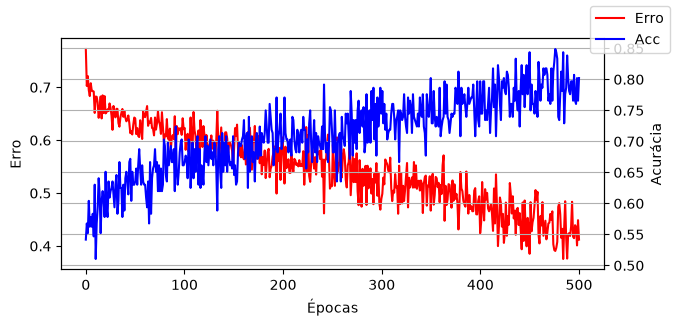

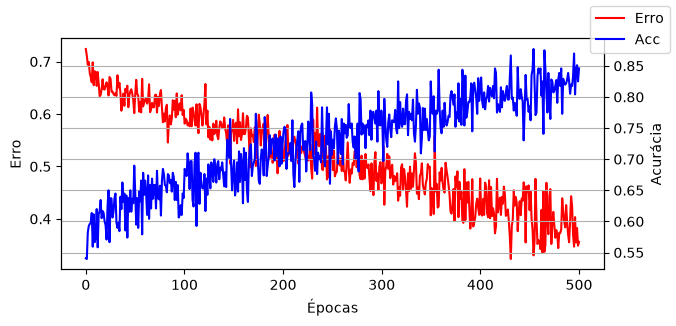

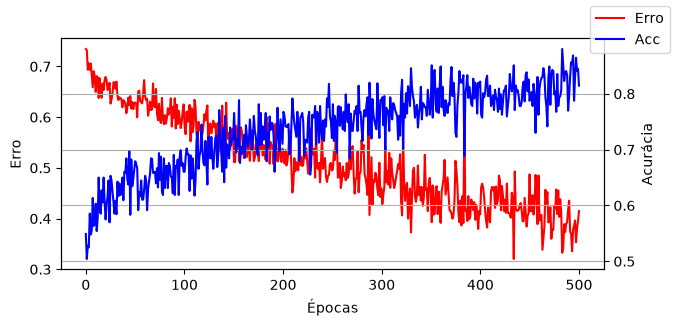

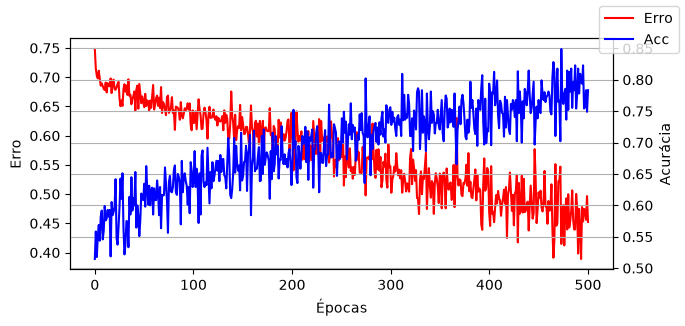

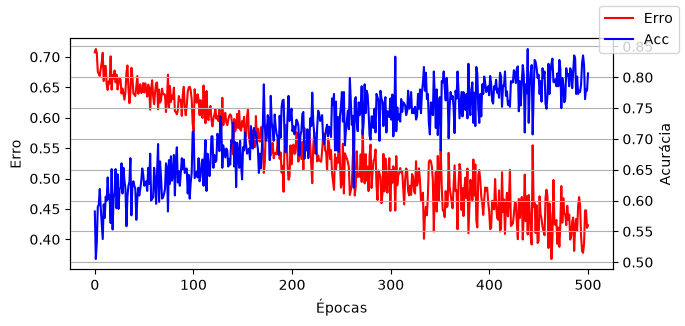

In [77]:
plot_loss(folds_loss, folds_acc)